In [4]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('/project/src')

from processing import grouped_barplot, grouped_lineplot

In [5]:
df = pd.read_csv("/project/data/hotel-booking-demand/hotel_bookings.csv")
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [6]:
missing = df.isna().sum()
missing[missing != 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

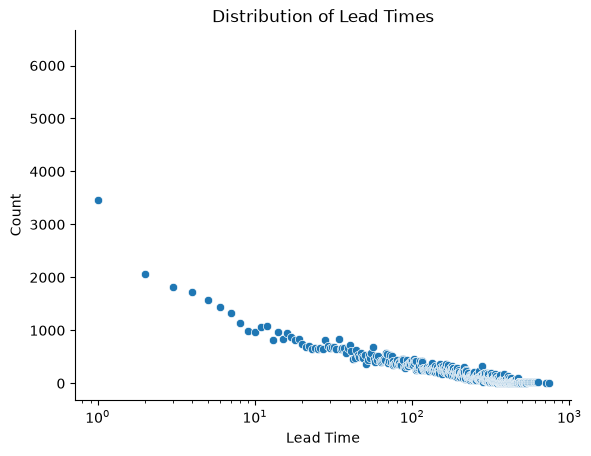

In [7]:
ax = sns.scatterplot(
    df['lead_time'].value_counts().sort_index().reset_index(),
    x = 'lead_time',
    y = 'count'
)
ax.set_xscale('log')
ax.set_title('Distribution of Lead Times')
ax.set_xlabel('Lead Time')
ax.set_ylabel('Count')
sns.despine(ax=ax)
plt.show()

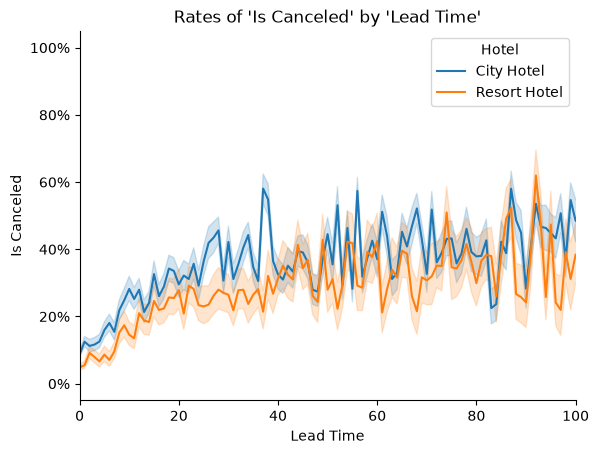

In [8]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', xlim=(0, 100))

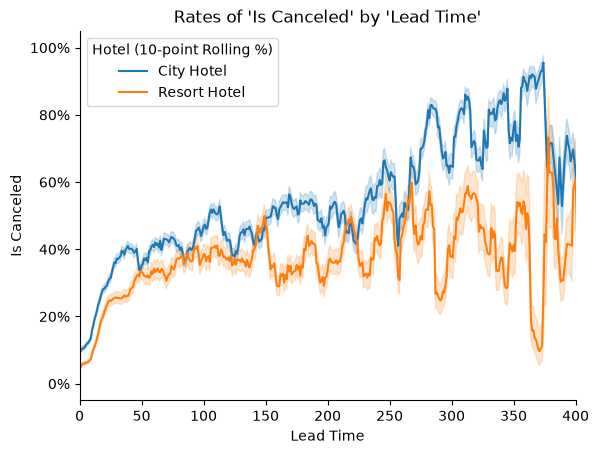

In [9]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', rolling_interval_width=10, xlim=(0, 400))

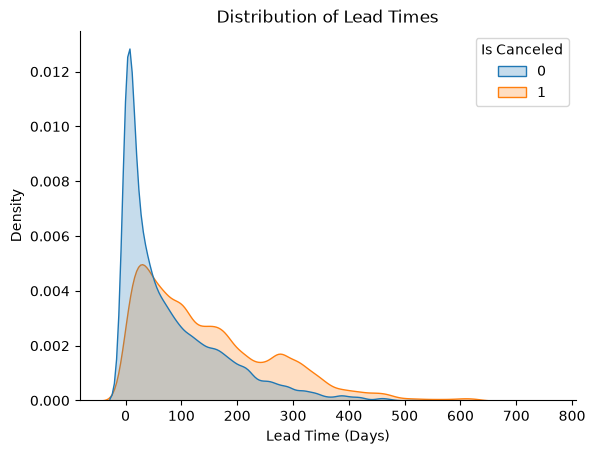

In [10]:
ax = sns.kdeplot(
    df,
    x='lead_time',
    hue='is_canceled',
    common_norm=False,
    fill=True
)
ax.set_title('Distribution of Lead Times')
ax.get_legend().set_title('Is Canceled')
ax.set_xlabel('Lead Time (Days)')
sns.despine(ax=ax)
plt.show()

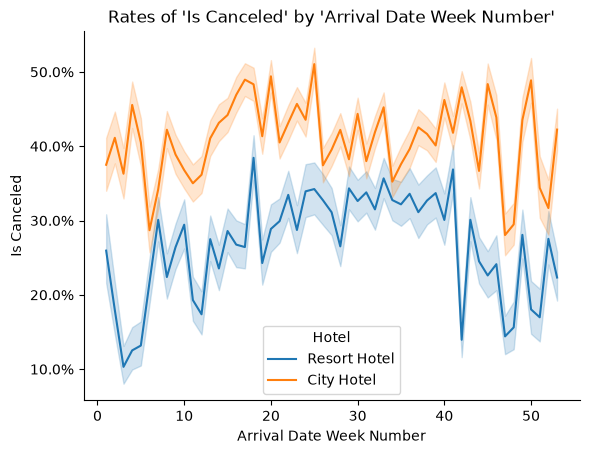

In [11]:
grouped_lineplot(df, 'arrival_date_week_number', 'is_canceled', 'hotel')

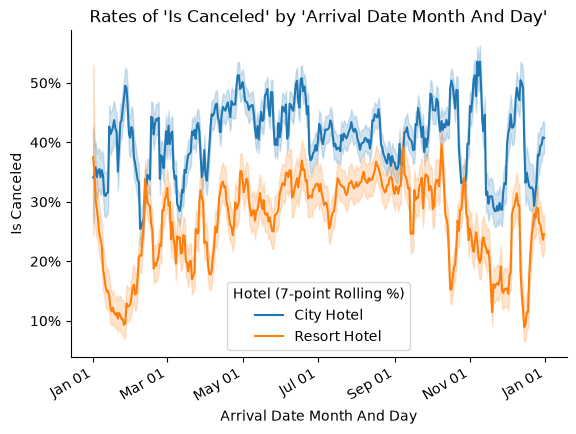

In [12]:
grouped_lineplot(
    df.assign(
        arrival_date_month_and_day=pd.to_datetime(
            '2000-'
            + df['arrival_date_month']
            + '-'
            + df['arrival_date_day_of_month'].astype(str),
            format='%Y-%B-%d'
        )
    ),
    'arrival_date_month_and_day',
    'is_canceled', 'hotel',
    rolling_interval_width=7,
    datetime_unit='days',
    remove_year=True
)

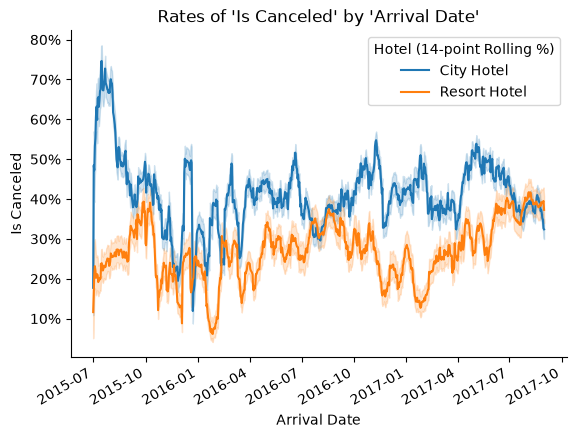

In [13]:
grouped_lineplot(
    df.assign(
        arrival_date=pd.to_datetime(
            df['arrival_date_year'].astype(str)
            + '-'
            + df['arrival_date_month']
            + '-'
            + df['arrival_date_day_of_month'].astype(str),
            format='%Y-%B-%d'
        )
    ),
    'arrival_date',
    'is_canceled',
    'hotel',
    rolling_interval_width=14,
    datetime_unit='days'
)

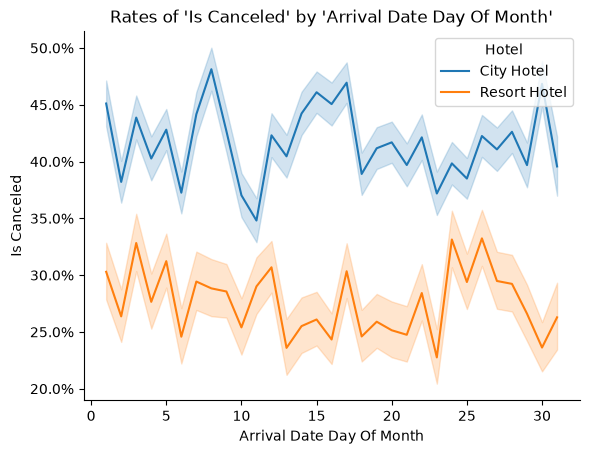

In [14]:
grouped_lineplot(df, 'arrival_date_day_of_month', 'is_canceled', 'hotel')

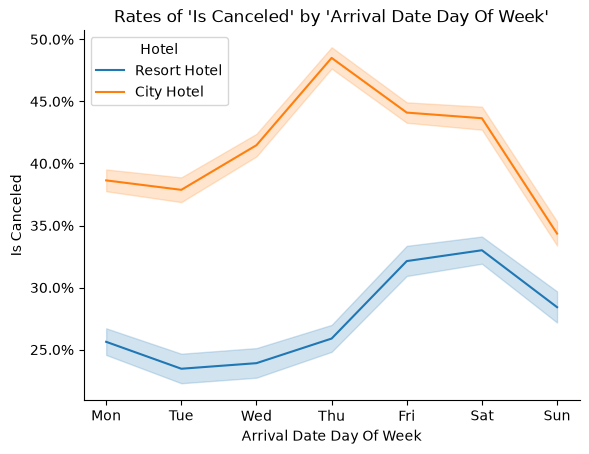

In [15]:
grouped_lineplot(
    df.assign(
        arrival_date_day_of_week=pd.to_datetime(
            df['arrival_date_year'].astype(str)
            + '-'
            + df['arrival_date_month']
            + '-'
            + df['arrival_date_day_of_month'].astype(str),
            format='%Y-%B-%d'
        ).dt.day_of_week
    ),
    'arrival_date_day_of_week',
    'is_canceled',
    'hotel',
    custom_labels={
        d: day
        for d, day in zip(
            [pd.Timestamp(f'2026-11-{9 + d}').day_of_week for d in range(7)],
            ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
        )
    }
)

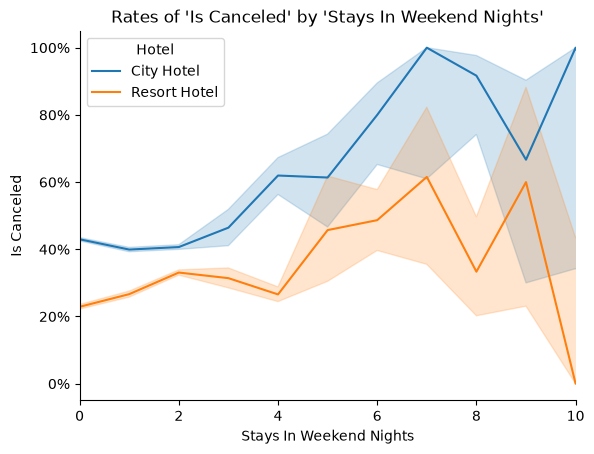

In [16]:
grouped_lineplot(df, 'stays_in_weekend_nights', 'is_canceled', 'hotel', xlim=(0, 10))

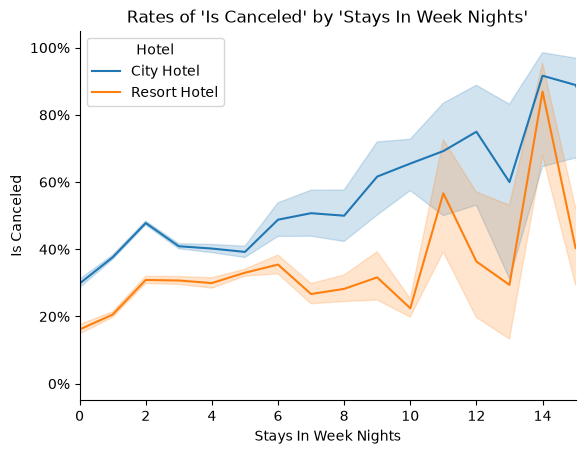

In [17]:
grouped_lineplot(df, 'stays_in_week_nights', 'is_canceled', 'hotel', xlim=(0, 15))

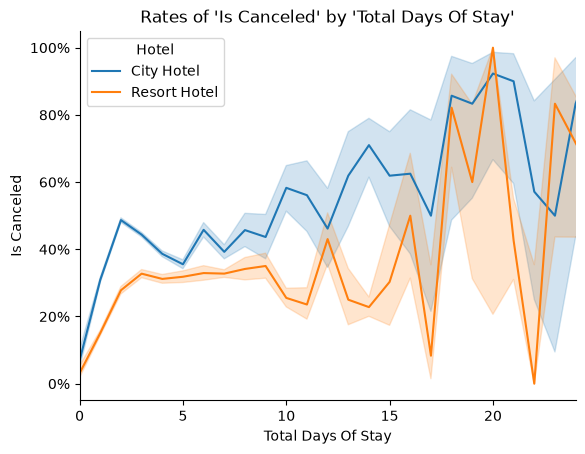

In [18]:
grouped_lineplot(
    df.assign(
        total_days_of_stay=df['stays_in_weekend_nights'] + df['stays_in_week_nights']
    ),
    'total_days_of_stay',
    'is_canceled',
    'hotel',
    xlim=(0, 24)
)

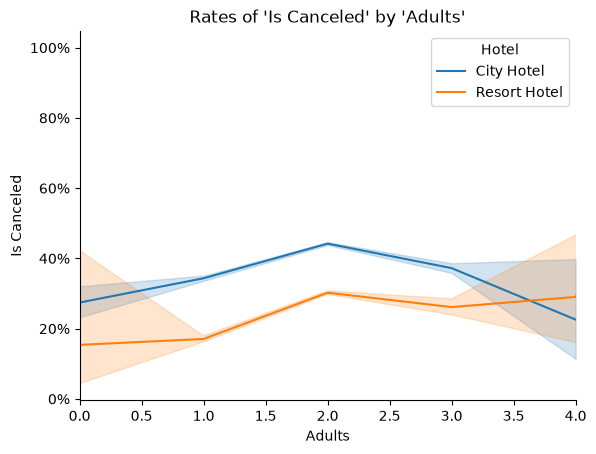

In [19]:
grouped_lineplot(df, 'adults', 'is_canceled', 'hotel', xlim=(0, 4))

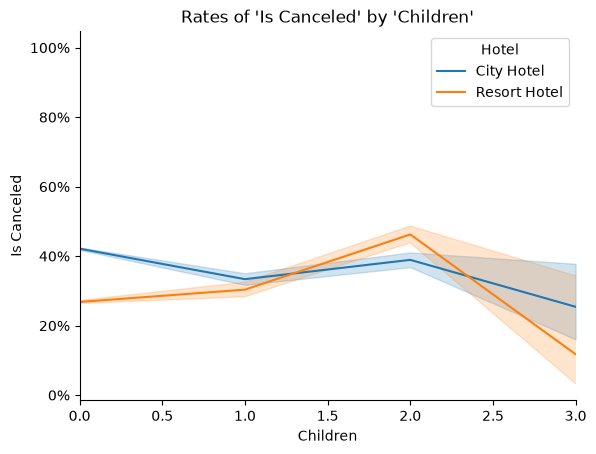

In [20]:
grouped_lineplot(df, 'children', 'is_canceled', 'hotel', xlim=(0, 3))

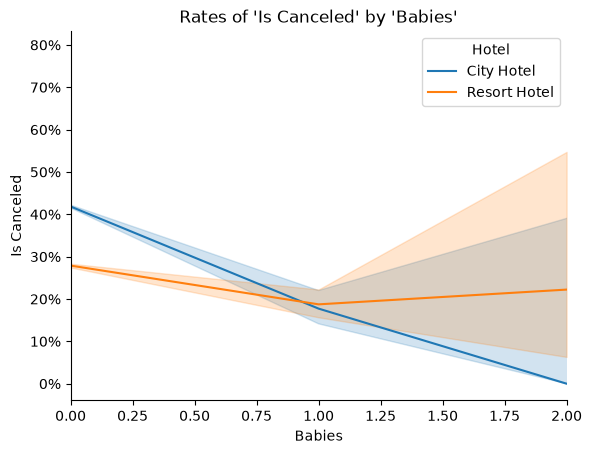

In [21]:
grouped_lineplot(df, 'babies', 'is_canceled', 'hotel', xlim=(0, 2))

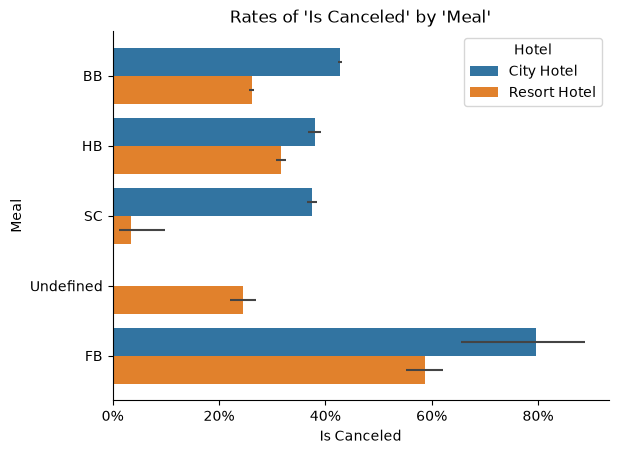

In [22]:
grouped_barplot(df, 'meal', 'is_canceled', 'hotel')

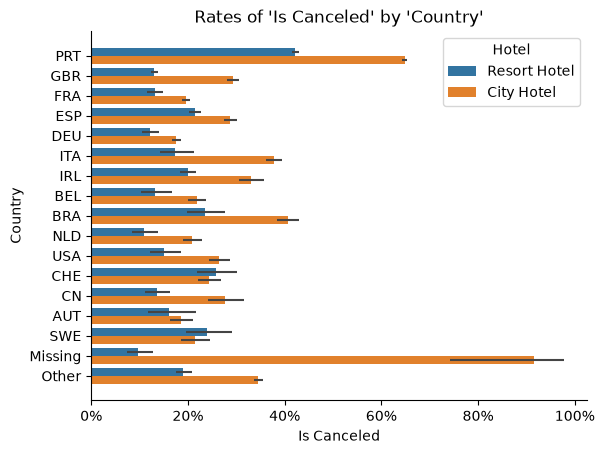

In [23]:
countries = df['country'].value_counts()
frequent_countries = countries[countries > 1000].index.tolist()
grouped_barplot(df, 'country', 'is_canceled', 'hotel', categories=frequent_countries + ['Missing'], other='Other')

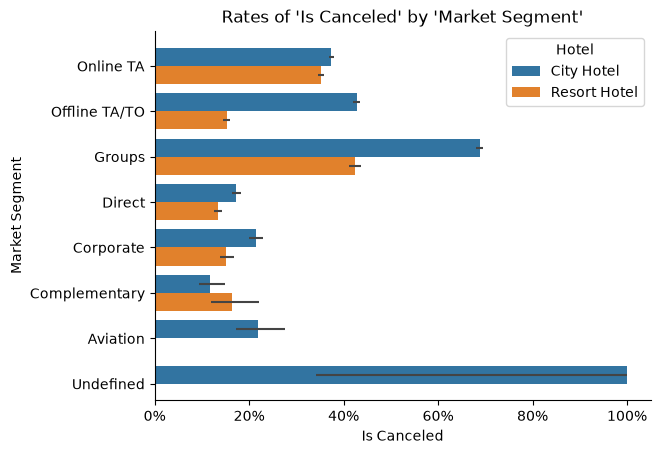

In [24]:
grouped_barplot(df, 'market_segment', 'is_canceled', 'hotel')

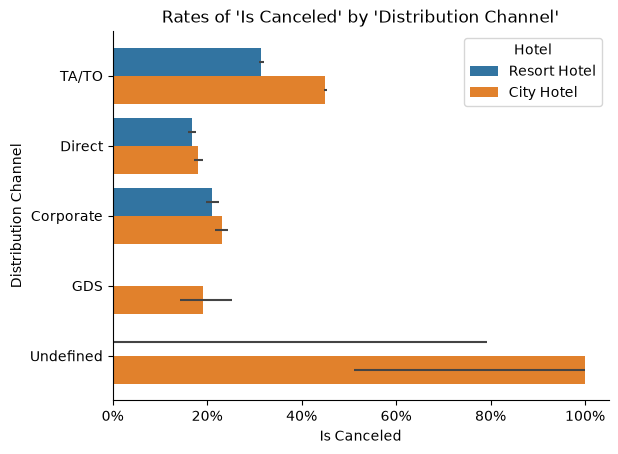

In [25]:
grouped_barplot(df, 'distribution_channel', 'is_canceled', 'hotel')

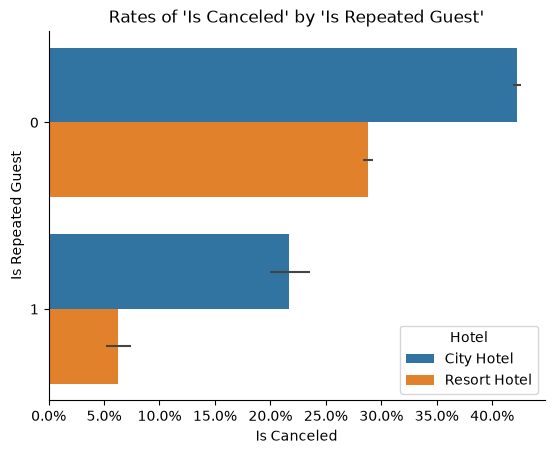

In [26]:
grouped_barplot(df, 'is_repeated_guest', 'is_canceled', 'hotel')

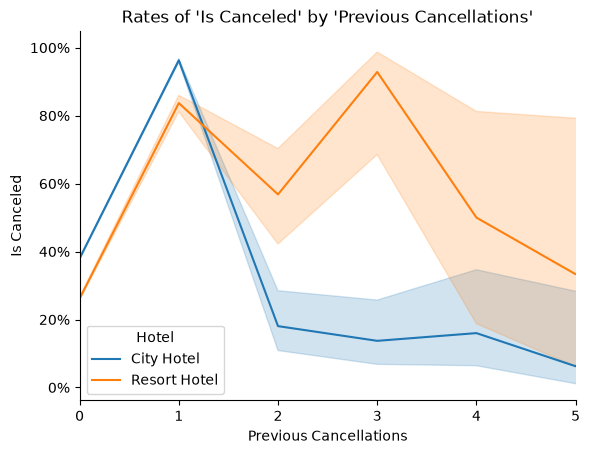

In [27]:
grouped_lineplot(df, 'previous_cancellations', 'is_canceled', 'hotel', xlim=(0, 5))

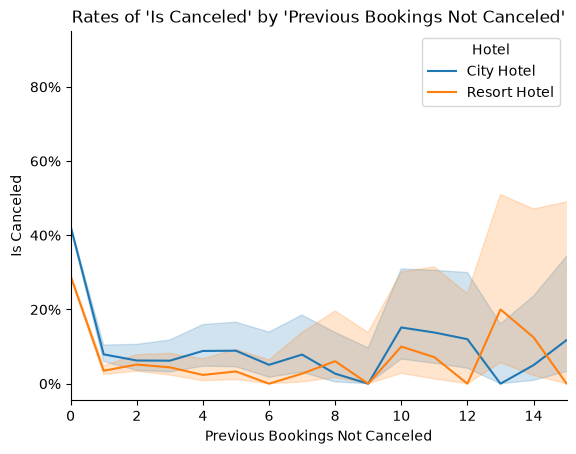

In [28]:
grouped_lineplot(df, 'previous_bookings_not_canceled', 'is_canceled', 'hotel', xlim=(0, 15))

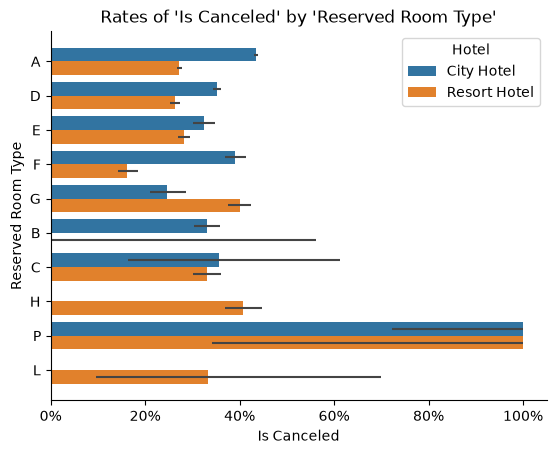

In [29]:
grouped_barplot(df, 'reserved_room_type', 'is_canceled', 'hotel')

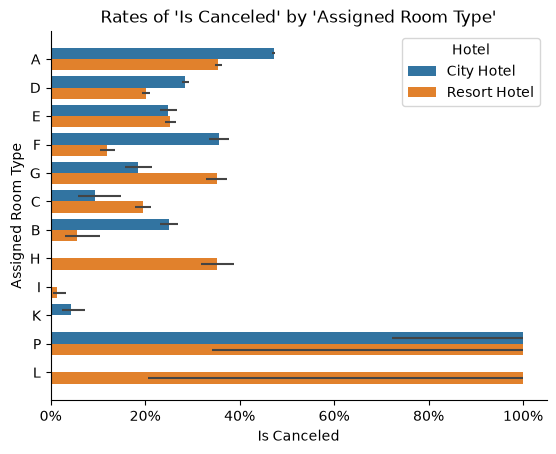

In [30]:
grouped_barplot(df, 'assigned_room_type', 'is_canceled', 'hotel')

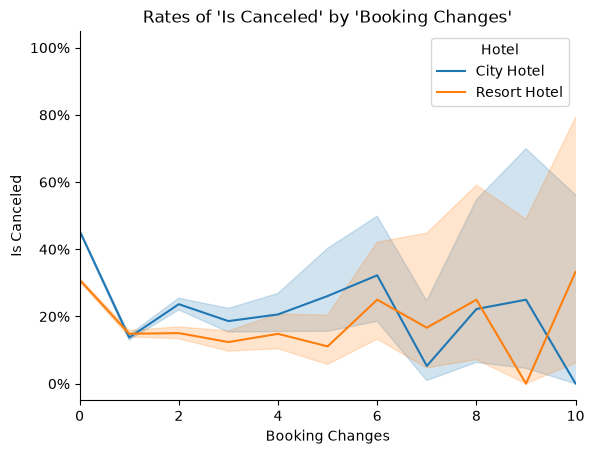

In [31]:
grouped_lineplot(df, 'booking_changes', 'is_canceled', 'hotel', xlim=(0, 10))

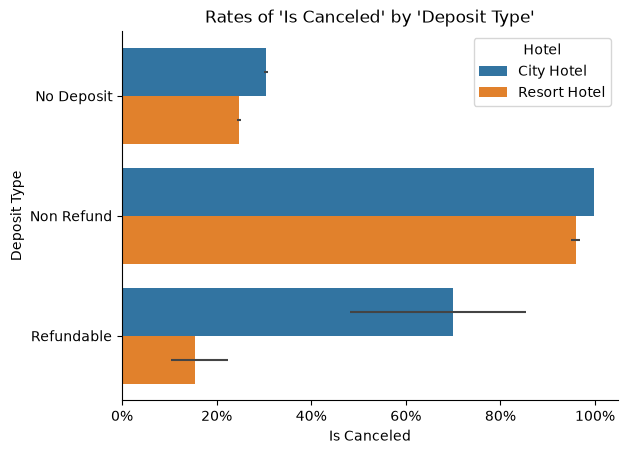

In [32]:
grouped_barplot(df, 'deposit_type', 'is_canceled', 'hotel')

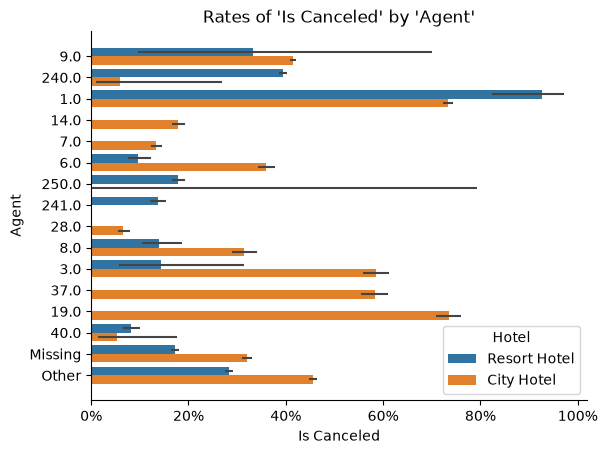

In [33]:
agents = df['agent'].value_counts()
frequent_agents = agents[agents > 1000].index.tolist()
grouped_barplot(df, 'agent', 'is_canceled', 'hotel', categories=frequent_agents + ['Missing'], other='Other')

In [184]:
y_indices

[('City Hotel', 'Canceled'),
 ('City Hotel', 'Not Canceled'),
 ('Resort Hotel', 'Canceled'),
 ('Resort Hotel', 'Not Canceled')]

In [203]:
min(bbox.x0 for bbox in label_bboxes)

np.float64(-0.10047789725209072)

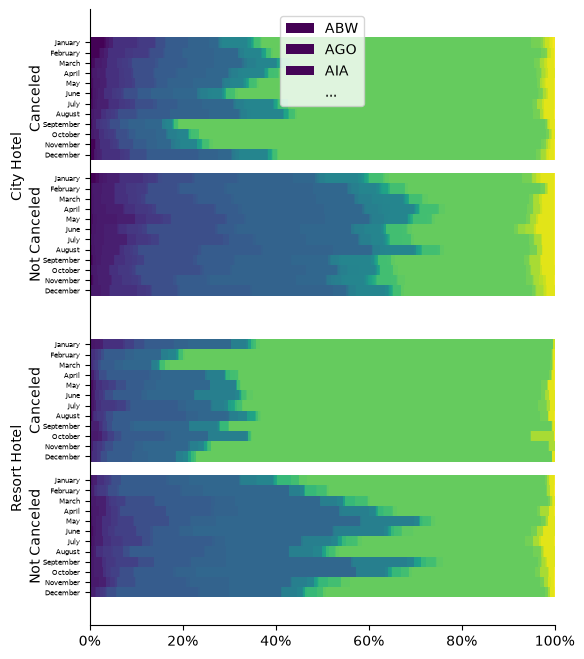

In [ ]:
import calendar
import numpy as np
import itertools
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

summary = (
    df.assign(is_canceled=np.where(df['is_canceled'], 'Canceled', 'Not Canceled'))
    .groupby(['hotel', 'is_canceled', 'arrival_date_month'], dropna=False)['country']
    .value_counts(normalize=True, dropna=False)
    .rename('p')
    .reset_index()
    .fillna('Missing')
)
hotel_values = sorted(summary['hotel'].unique())
canceled_values = sorted(summary['is_canceled'].unique())
arrival_date_month_values = sorted(summary['arrival_date_month'].unique())
country_values = sorted(summary['country'].unique())

cmap = plt.colormaps['viridis']

country_colors = {
    country: cmap(int(256.0 * i / len(country_values)))
    for i, country in enumerate(country_values)
}

months_ordered = [
    m
    for m in calendar.month_name[1:13]
    if m in arrival_date_month_values
]
months = months_ordered + [
    m
    for m in arrival_date_month_values
    if m not in months_ordered
]
num_months = len(months)

fig, ax = plt.subplots(figsize=(6, 8))

y_indices = list(itertools.product(hotel_values, canceled_values))

hotel_ticks = np.linspace(
    1,
    0,
    2 * len(hotel_values),
    endpoint=False
)

hotel_margin = 0.9 * (hotel_ticks[0] - hotel_ticks[1])
hotel_ticks = hotel_ticks[np.arange(len(hotel_values)) * 2 + 1]

canceled_ticks = np.linspace(
    hotel_ticks + hotel_margin,
    hotel_ticks - hotel_margin,
    2 * len(canceled_values),
    endpoint=False
)

canceled_margin = 0.9 * (canceled_ticks[0][0] - canceled_ticks[1][0])
canceled_ticks = canceled_ticks[np.arange(len(canceled_values)) * 2 + 1].T.flatten()

month_ticks = np.linspace(
    canceled_ticks + canceled_margin,
    canceled_ticks - canceled_margin,
    2 * len(months),
    endpoint=False
)

month_margin = month_ticks[0][0] - month_ticks[1][0]
month_ticks = month_ticks[np.arange(len(months)) * 2 + 1]

for i, month in enumerate(months):

    left = np.zeros(len(y_indices))

    for j, country in enumerate(country_values):

        values = (
            summary.loc[
                (summary['arrival_date_month'] == month)
                & (summary['country'] == country)
            ]
            .set_index(['hotel', 'is_canceled'])['p']
            .reindex(y_indices, fill_value=0)
        )
            
        ax.barh(
            y=month_ticks[i],
            width=values,
            height=2 * month_margin,
            left=left,
            color=country_colors[country]
        )

        left += values

ax.set_yticks(month_ticks.T.flatten())
ax.set_yticklabels(months * len(y_indices), size=5)

fig.canvas.draw()
ylabels_x = min(
    (
        ax
        .transData
        .inverted()
        .transform_bbox(label.get_window_extent(renderer=fig.canvas.get_renderer()))
        .x0
    )
    for label in ax.get_yticklabels()
    if label.get_visible()
)

for i, hotel in enumerate(hotel_values):
    for j, canceled_status in enumerate(canceled_values):
        ax.text(
            x=ylabels_x,
            y=canceled_ticks[2 * i + j],
            s=canceled_status,
            rotation=90,
            verticalalignment='center',
            horizontalalignment='right'
        )
    ax.text(
        x=ylabels_x - 0.04,
        y=hotel_ticks[i],
        s=hotel,
        rotation=90,
        verticalalignment='center',
        horizontalalignment='right'
    )

from matplotlib.patches import Patch

handles = [
    Patch(facecolor=color, label=label)
    for label, color in list(country_colors.items())[:3]
]

handles.append(Patch(facecolor="none", edgecolor="none", label="..."))

ax.legend(handles=handles, loc="best", frameon=True)

ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

sns.despine(ax=ax)
fig.show()

In [192]:
ylabel_width

np.float64(37.0)

In [190]:
y_indices

[('City Hotel', 'Canceled'),
 ('City Hotel', 'Not Canceled'),
 ('Resort Hotel', 'Canceled'),
 ('Resort Hotel', 'Not Canceled')]

In [90]:
month_ticks

array([[0.0446875, 0.2696875, 0.5446875, 0.7696875],
       [0.0615625, 0.2865625, 0.5615625, 0.7865625],
       [0.0784375, 0.3034375, 0.5784375, 0.8034375],
       [0.0953125, 0.3203125, 0.5953125, 0.8203125],
       [0.1121875, 0.3371875, 0.6121875, 0.8371875],
       [0.1290625, 0.3540625, 0.6290625, 0.8540625],
       [0.1459375, 0.3709375, 0.6459375, 0.8709375],
       [0.1628125, 0.3878125, 0.6628125, 0.8878125],
       [0.1796875, 0.4046875, 0.6796875, 0.9046875],
       [0.1965625, 0.4215625, 0.6965625, 0.9215625],
       [0.2134375, 0.4384375, 0.7134375, 0.9384375],
       [0.2303125, 0.4553125, 0.7303125, 0.9553125]])

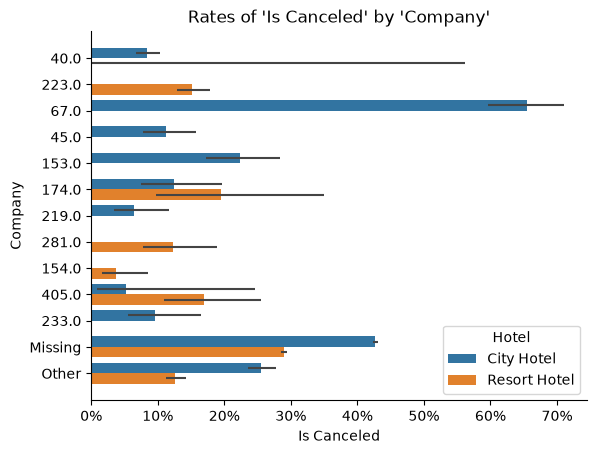

In [32]:
companies = df['company'].value_counts()
frequent_companies = companies[companies > 100].index.tolist()
grouped_barplot(df, 'company', 'is_canceled', 'hotel', categories=frequent_companies + ['Missing'], other='Other')

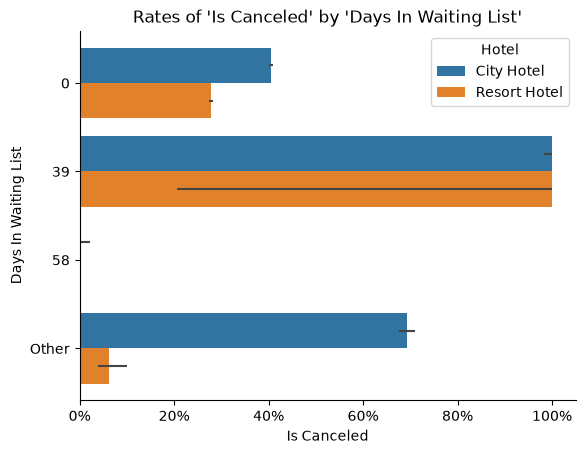

In [33]:
waiting_days = df['days_in_waiting_list'].value_counts()
frequent_waiting_days = waiting_days[waiting_days > 150].index.tolist()
grouped_barplot(df, 'days_in_waiting_list', 'is_canceled', 'hotel', categories=frequent_waiting_days, other='Other')

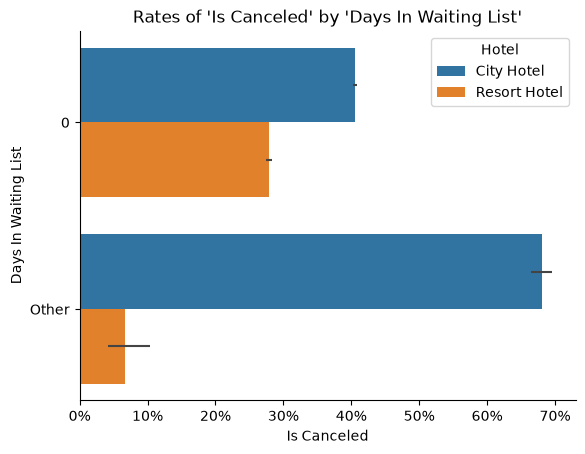

In [34]:
grouped_barplot(df, 'days_in_waiting_list', 'is_canceled', 'hotel', categories=[0], other='Other')

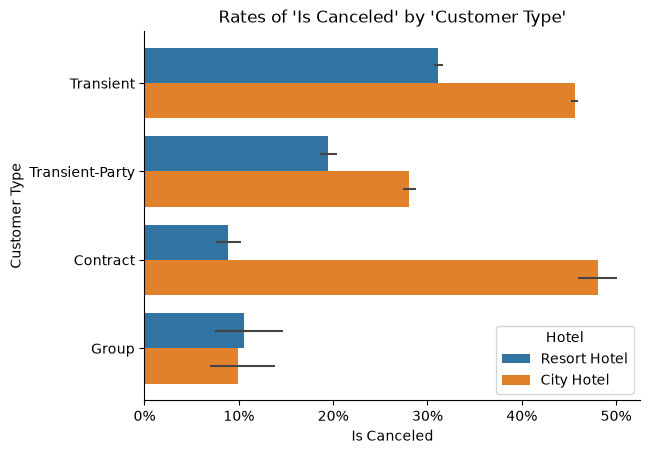

In [35]:
grouped_barplot(df, 'customer_type', 'is_canceled', 'hotel')

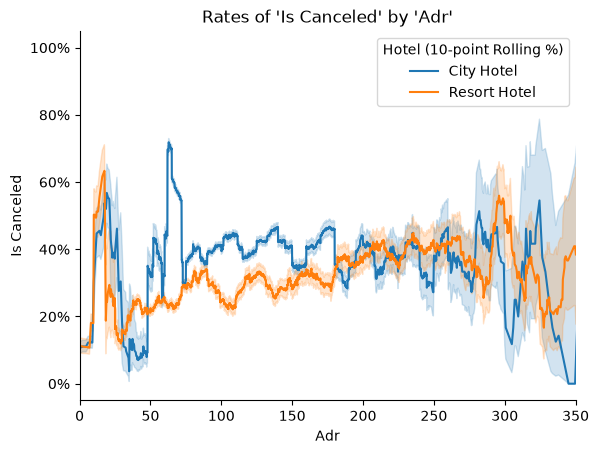

In [36]:
grouped_lineplot(df, 'adr', 'is_canceled', 'hotel', rolling_interval_width=10, xlim=(0, 350))

Interestingly, customers who required car parking spaces 

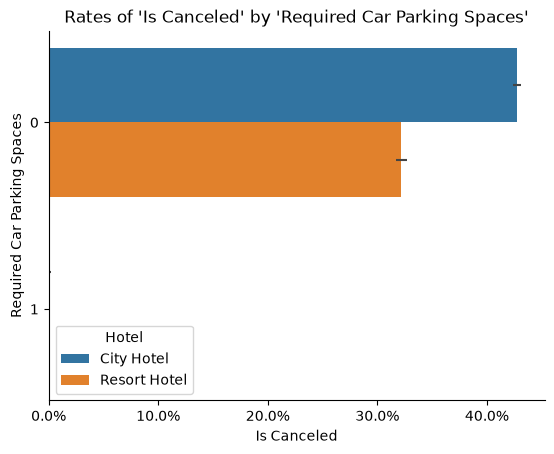

In [37]:
grouped_barplot(df, 'required_car_parking_spaces', 'is_canceled', 'hotel', categories=[0, 1])

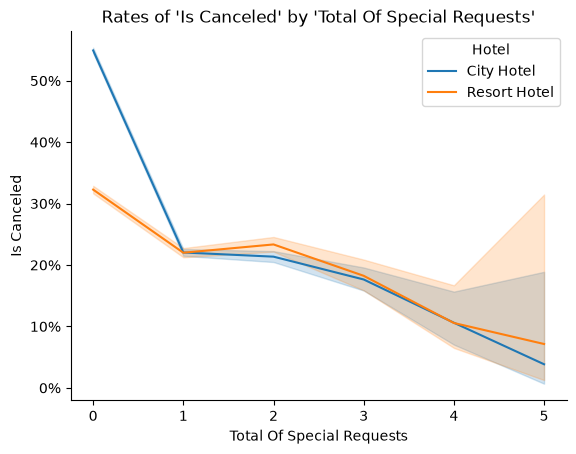

In [38]:
grouped_lineplot(df, 'total_of_special_requests', 'is_canceled', 'hotel')

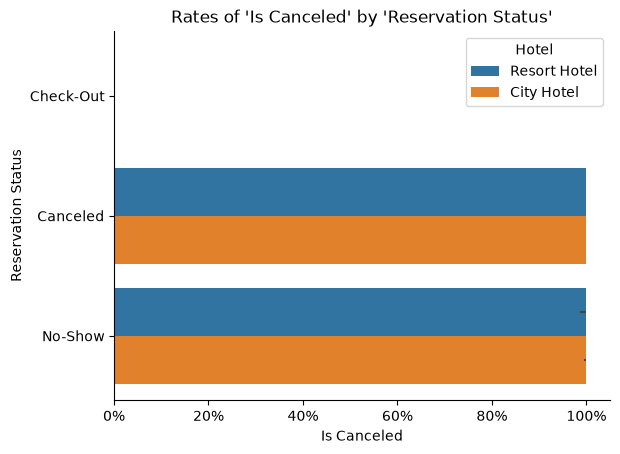

In [39]:
grouped_barplot(df, 'reservation_status', 'is_canceled', 'hotel')

In [40]:
df.assign(
    days_from_arrival_status_changed=(
        pd.to_datetime(df['reservation_status_date'])
        - pd.to_datetime(
            df['arrival_date_year'].astype(str)
            + '-'
            + df['arrival_date_month']
            + '-'
            + df['arrival_date_day_of_month'].astype(str),
            format='%Y-%B-%d'
        )
    ).dt.days
).loc[df['reservation_status'] == 'Canceled', 'days_from_arrival_status_changed'].value_counts().sort_index()

days_from_arrival_status_changed
-526     17
-519     17
-512     17
-505     17
-498     17
       ... 
-4      581
-3      718
-2      487
-1      630
 0      881
Name: count, Length: 391, dtype: int64

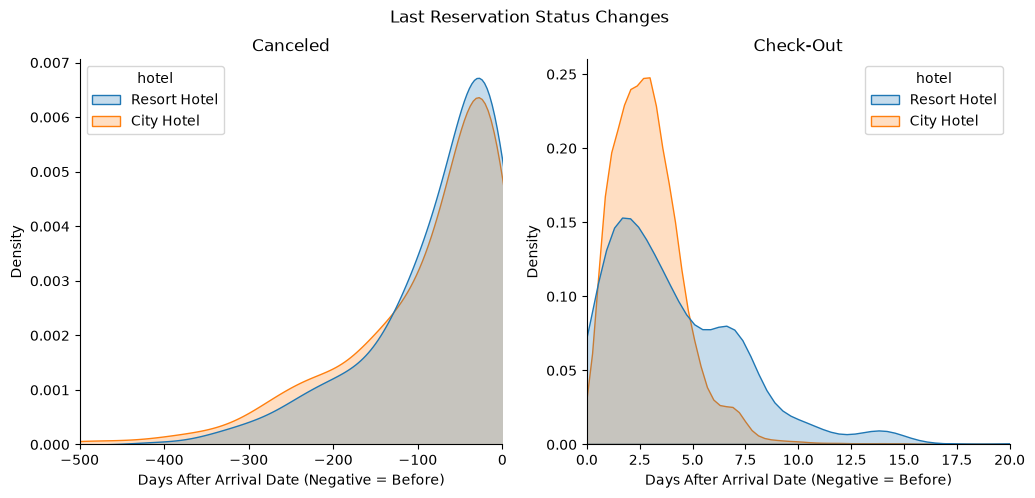

In [41]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
for ax, s, lims in zip(axes, ['Canceled', 'Check-Out'], [(-500, 0), (0, 20)]):
    sns.kdeplot(
        df.assign(
            days_from_arrival_status_changed=(
                pd.to_datetime(df['reservation_status_date'])
                - pd.to_datetime(
                    df['arrival_date_year'].astype(str)
                    + '-'
                    + df['arrival_date_month']
                    + '-'
                    + df['arrival_date_day_of_month'].astype(str),
                    format='%Y-%B-%d'
                )
            ).dt.days
        ).loc[df['reservation_status'] == s],
        x='days_from_arrival_status_changed',
        hue='hotel',
        bw_adjust=2.5,
        fill=True,
        common_norm=False,
        ax=ax
    )
    ax.set_title(s)
    ax.set_xlabel('Days After Arrival Date (Negative = Before)')
    ax.set_xlim(lims)
    sns.despine(ax=ax)
fig.suptitle('Last Reservation Status Changes')
fig.show()

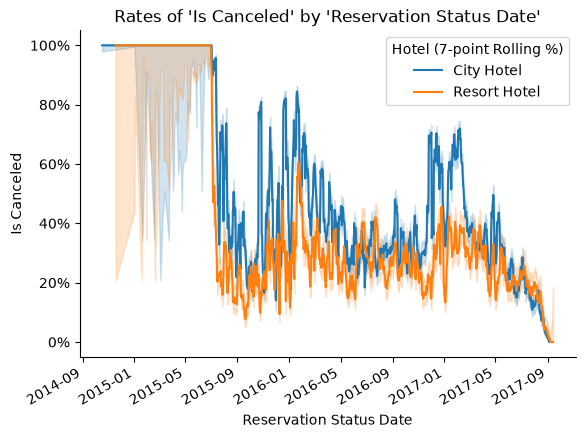

In [42]:
grouped_lineplot(
    df.assign(reservation_status_date=pd.to_datetime(df['reservation_status_date'])),
    'reservation_status_date',
    'is_canceled',
    'hotel',
    rolling_interval_width=7,
    datetime_unit='days'
)

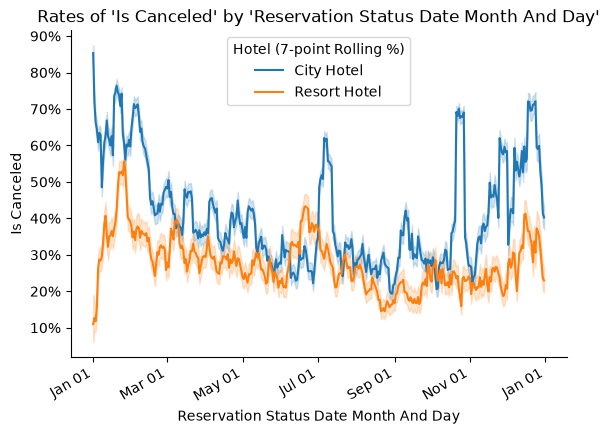

In [43]:
grouped_lineplot(
    df.assign(
        reservation_status_date_month_and_day=pd.to_datetime(
            '2000-' + pd.to_datetime(df['reservation_status_date']).dt.strftime('%m-%d'),
            format='%Y-%m-%d'
        )
    ),
    'reservation_status_date_month_and_day',
    'is_canceled',
    'hotel',
    rolling_interval_width=7,
    datetime_unit='days',
    remove_year=True
)

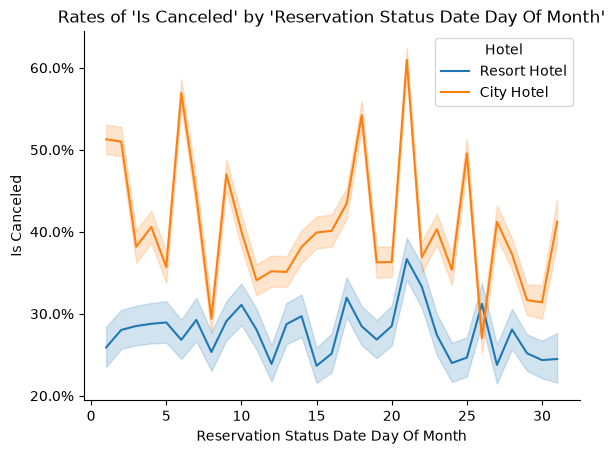

In [44]:
grouped_lineplot(
    df.assign(
        reservation_status_date_day_of_month=pd.to_datetime(
            df['reservation_status_date']
        ).dt.day
    ),
    'reservation_status_date_day_of_month',
    'is_canceled',
    'hotel'
)

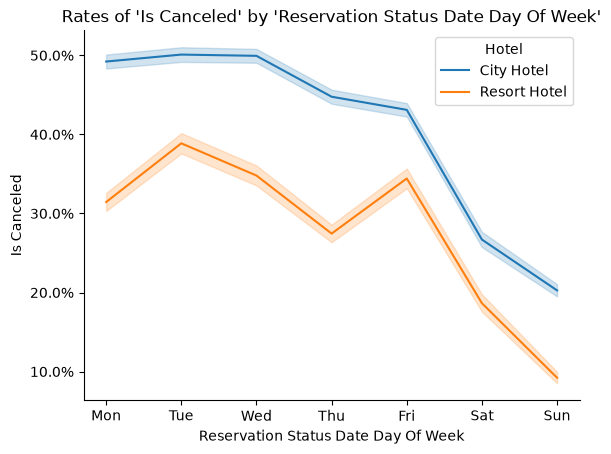

In [45]:
grouped_lineplot(
    df.assign(
        reservation_status_date_day_of_week=pd.to_datetime(
            df['reservation_status_date']
        ).dt.day_of_week
    ),
    'reservation_status_date_day_of_week',
    'is_canceled',
    'hotel',
    custom_labels={
        d: day
        for d, day in zip(
            [pd.Timestamp(f'2026-11-{9 + d}').day_of_week for d in range(7)],
            ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
        )
    }
)

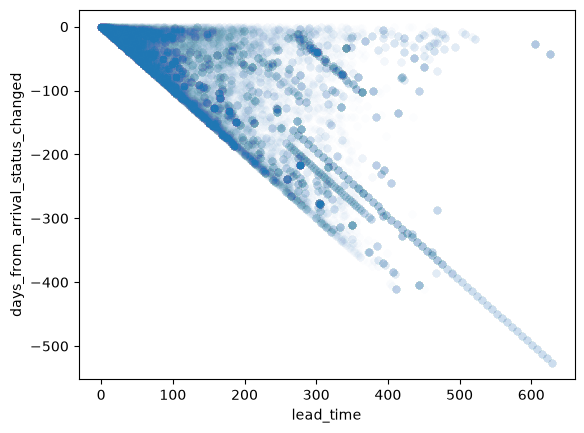

In [46]:
ax = sns.scatterplot(
    df.assign(
        days_from_arrival_status_changed=(
            pd.to_datetime(df['reservation_status_date'])
            - pd.to_datetime(
                df['arrival_date_year'].astype(str)
                + '-'
                + df['arrival_date_month']
                + '-'
                + df['arrival_date_day_of_month'].astype(str),
                format='%Y-%B-%d'
            )
        ).loc[df['reservation_status'] == 'Canceled'].dt.days
    ),
    x='lead_time',
    y='days_from_arrival_status_changed',
    alpha=0.01
)

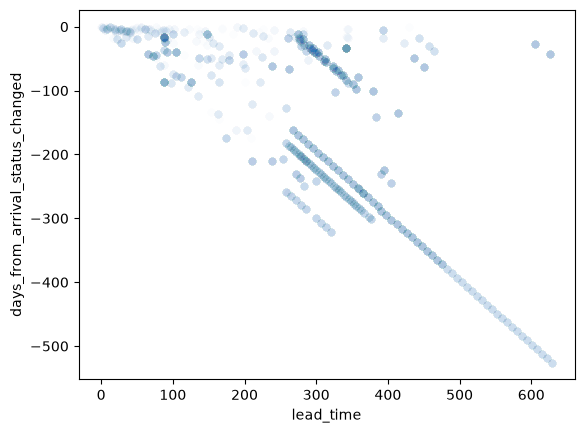

In [47]:
ax = sns.scatterplot(
    df.assign(
        days_from_arrival_status_changed=(
            pd.to_datetime(df['reservation_status_date'])
            - pd.to_datetime(
                df['arrival_date_year'].astype(str)
                + '-'
                + df['arrival_date_month']
                + '-'
                + df['arrival_date_day_of_month'].astype(str),
                format='%Y-%B-%d'
            )
        ).dt.days
    ).loc[(df['agent'] == 1) & (df['reservation_status'] == 'Canceled')],
    x='lead_time',
    y='days_from_arrival_status_changed',
    alpha=0.01
)
plt.show()

In [50]:
df.style.background_gradient(cmap="Blues")

KeyboardInterrupt: 

In [49]:
test_df = test_df.loc[test_df['within_line']]

NameError: name 'test_df' is not defined

In [ ]:
test_df['arrival_date'] = pd.to_datetime(
    test_df['arrival_date_year'].astype(str)
    + '-'
    + test_df['arrival_date_month']
    + '-'
    + test_df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)

In [ ]:
df['agent'].value_counts().head(50)

agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
6.0       3290
250.0     2870
241.0     1721
28.0      1666
8.0       1514
3.0       1336
37.0      1230
19.0      1061
40.0      1039
314.0      927
21.0       875
229.0      786
242.0      780
83.0       696
29.0       683
171.0      607
12.0       578
85.0       554
20.0       540
96.0       537
243.0      514
30.0       484
134.0      482
298.0      472
27.0       450
15.0       402
26.0       401
11.0       395
22.0       382
56.0       375
273.0      349
177.0      347
86.0       338
58.0       335
5.0        330
119.0      304
196.0      301
34.0       294
44.0       292
138.0      287
315.0      284
38.0       274
10.0       260
236.0      247
16.0       246
Name: count, dtype: int64

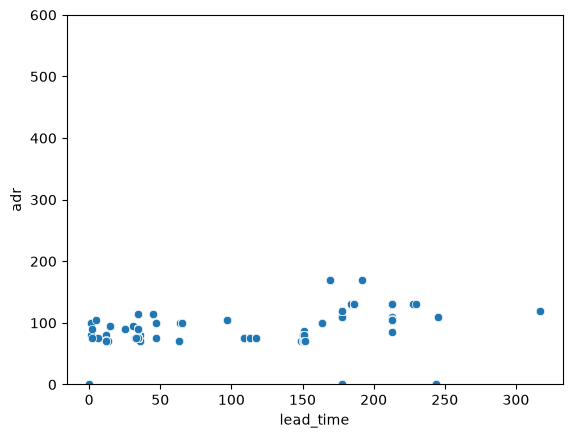

In [ ]:
ax = sns.scatterplot(
    df.loc[df['agent'] == 19],
    x='lead_time',
    y='adr'
)
ax.set_ylim(0, 600)
plt.show()